In [1]:
import seaborn as sns
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython import display
display.set_matplotlib_formats('svg')

/tmp/ipykernel_129389/3288856679.py:7: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  display.set_matplotlib_formats('svg')


In [2]:
iris = sns.load_dataset('iris')

iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
data = torch.tensor(iris[iris.columns[0:4]].values).float()
labels = torch.zeros(len(data), dtype=torch.long)
labels[iris.species=='versicolor']=1
labels[iris.species=='virginica']=2
labels

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2])

In [4]:
def createIrismodel(nHidden):
    ANNiris = nn.Sequential(
        nn.Linear(4,nHidden),
        nn.ReLU(),
        nn.Linear(nHidden,nHidden),
        nn.ReLU(),
        nn.Linear(nHidden,3),
    )
    lossfun = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(ANNiris.parameters(),lr=.01)
    return ANNiris, lossfun, optimizer

In [5]:
def trainThemodel(ANNiris):
    losses = torch.zeros(numepochs)
    ongoingAcc = []

    for epochi in range(numepochs):
        yHat = ANNiris(data)
        loss = lossfun(yHat, labels)
        losses[epochi] = loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    predictions = ANNiris(data)
    predlabels = torch.argmax(predictions,axis=1)
    return 100*torch.mean((predlabels==labels).float())

In [7]:
numepochs = 150
numhidden = np.arange(1,129)
accuracies = []

for nunits in numhidden:
    ANNiris, lossfun, optimizer = createIrismodel(nunits)
    acc = trainThemodel(ANNiris)
    accuracies.append(acc)



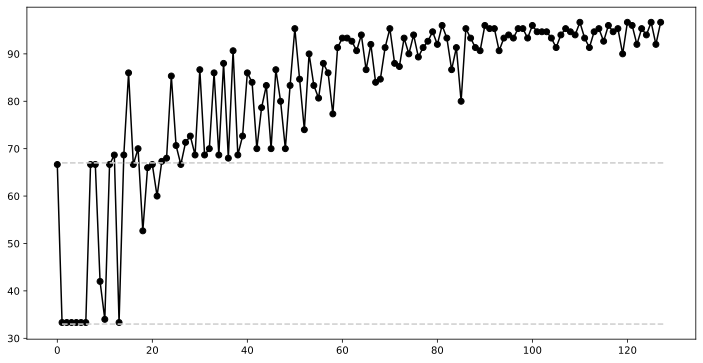

In [10]:
fig,ax = plt.subplots(1, figsize=(12,6))
ax.plot(accuracies, 'ko-')
ax.plot(numhidden[[0,-1]], [33,33], '--', color=[.8,.8,.8])
ax.plot(numhidden[[0,-1]], [67,67], '--', color=[.8,.8,.8])
plt.show()

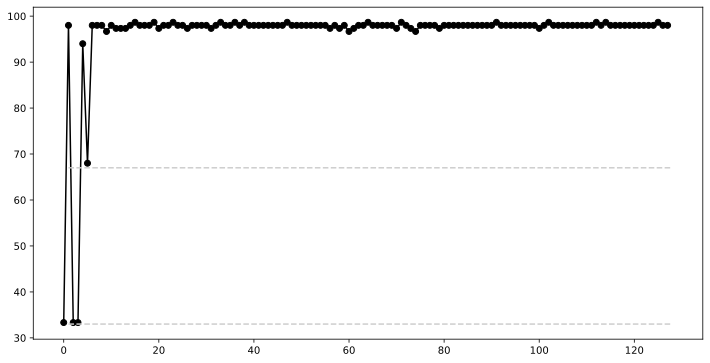

In [11]:
numepochs = 1000
numhidden = np.arange(1,129)
accuracies = []

for nunits in numhidden:
    ANNiris, lossfun, optimizer = createIrismodel(nunits)
    acc = trainThemodel(ANNiris)
    accuracies.append(acc)

fig,ax = plt.subplots(1, figsize=(12,6))
ax.plot(accuracies, 'ko-')
ax.plot(numhidden[[0,-1]], [33,33], '--', color=[.8,.8,.8])
ax.plot(numhidden[[0,-1]], [67,67], '--', color=[.8,.8,.8])
plt.show()

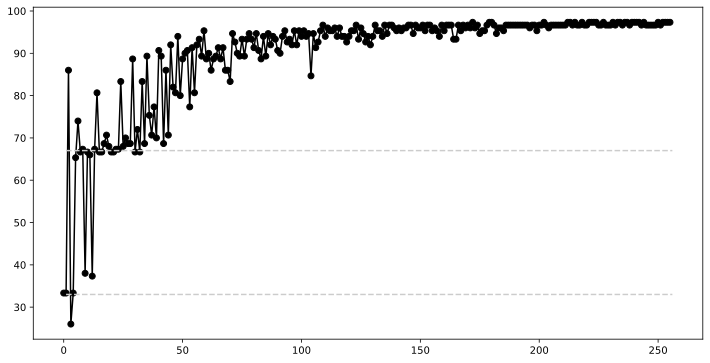

In [12]:
numepochs = 150
numhidden = np.arange(1,257)
accuracies = []

for nunits in numhidden:
    ANNiris, lossfun, optimizer = createIrismodel(nunits)
    acc = trainThemodel(ANNiris)
    accuracies.append(acc)

fig,ax = plt.subplots(1, figsize=(12,6))
ax.plot(accuracies, 'ko-')
ax.plot(numhidden[[0,-1]], [33,33], '--', color=[.8,.8,.8])
ax.plot(numhidden[[0,-1]], [67,67], '--', color=[.8,.8,.8])
plt.show()

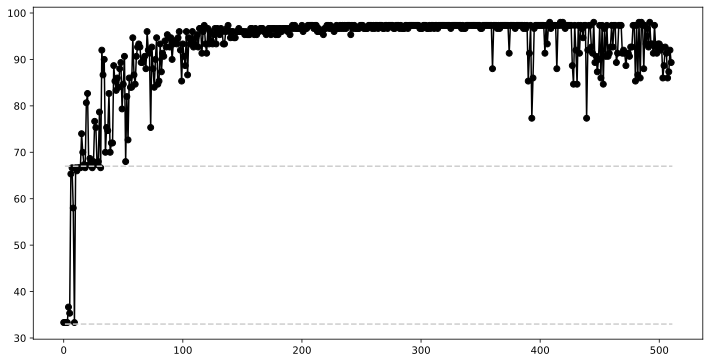

In [13]:
numepochs = 150
numhidden = np.arange(1,512)
accuracies = []

for nunits in numhidden:
    ANNiris, lossfun, optimizer = createIrismodel(nunits)
    acc = trainThemodel(ANNiris)
    accuracies.append(acc)

fig,ax = plt.subplots(1, figsize=(12,6))
ax.plot(accuracies, 'ko-')
ax.plot(numhidden[[0,-1]], [33,33], '--', color=[.8,.8,.8])
ax.plot(numhidden[[0,-1]], [67,67], '--', color=[.8,.8,.8])
plt.show()